# Pseudo-Label: The Simple and Efficient Semi-Supervised Learning Method for Deep Neural Networks
### Reproduction of Dong-Hyun Lee (ICMLW 2013) — DAE Pre-training + Pseudo-Label (`+PL+DAE`)

This notebook reproduces the complete semi-supervised pipeline of Dong-Hyun Lee (2013) on MNIST across 3 random splits:
- **Denoising Autoencoder (DAE) Pre-training**: 784 -> 5000 -> 784 with tied weights, unscaled 50% masking noise on inputs and hidden units, trained for 300 epochs on 59,000 unlabelled training images.
- **Weight Transfer**: Fine-tuning weight initialization scaled by $(1 - p_{in}) = 0.5$ into DropNN.
- **Pseudo-Label Fine-Tuning**: Linear ramp-up schedule $\alpha(t)$ ($T_1=200, T_2=800$) with annealed SGD learning rate ($\epsilon_0 = 1.5$) and momentum ($p(t) \to 0.99$).
- **Evaluation**: Table 2 test error (3-seed mean ± std) across $n \in \{100, 600, 1000, 3000\}$, Table 1 conditional entropy, Figure 1 t-SNE clusters, and Figure 2 filter evolution (DAE vs +PL+DAE).

## Colab / Path Setup & Imports


In [1]:
# Standalone Colab snippet:
# !git clone https://github.com/marcsanchezsala/semi-supervised-mnist.git
# %cd semi-supervised-mnist/02_DAE_pretraining
import os
import sys

if os.path.isdir("02_DAE_pretraining"):
    os.chdir("02_DAE_pretraining")
if "." not in sys.path:
    sys.path.append(".")

import matplotlib.pyplot as plt
import numpy as np
from sklearn.manifold import TSNE
import torch
import torch.nn.functional as F
import torchvision

from model import DenoisingAutoencoder, DropNN, bce_sum_loss, conditional_entropy

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cuda


## 1. MNIST Semi-Supervised Data Split (Section 4.1)


In [2]:
# Download MNIST train (60k) and test (10k)
mnist_train = torchvision.datasets.MNIST(root="./data", train=True, download=True)
mnist_test = torchvision.datasets.MNIST(root="./data", train=False, download=True)

# Flatten and normalize to [0, 1] float32 directly on device (188 MB) to bypass Colab DataLoader bottleneck
X_train = (mnist_train.data.float() / 255.0).view(-1, 784).to(device)
y_train = mnist_train.targets.to(device)
X_test = (mnist_test.data.float() / 255.0).view(-1, 784).to(device)
y_test = mnist_test.targets.to(device)


def make_splits(X: torch.Tensor, y: torch.Tensor, n_labeled: int, n_val: int = 1000, seed: int = 42):
    g = torch.Generator().manual_seed(seed)
    n_classes = 10
    val_per_class = n_val // n_classes
    lab_per_class = n_labeled // n_classes

    val_idx, lab_idx, unlab_idx = [], [], []
    for c in range(n_classes):
        c_idx = (y == c).nonzero(as_tuple=True)[0]
        c_perm = torch.randperm(len(c_idx), generator=g)
        c_shuffled = c_idx[c_perm.to(c_idx.device)]
        val_idx.append(c_shuffled[:val_per_class])
        lab_idx.append(c_shuffled[val_per_class : val_per_class + lab_per_class])
        unlab_idx.append(c_shuffled[val_per_class + lab_per_class :])

    idx_v = torch.cat(val_idx)
    idx_l = torch.cat(lab_idx)
    idx_u = torch.cat(unlab_idx)

    assert len(idx_v) == n_val, f"Validation size mismatch: {len(idx_v)} != {n_val}"
    assert len(idx_l) == n_labeled, f"Labeled size mismatch: {len(idx_l)} != {n_labeled}"
    assert len(idx_u) == len(X) - n_val - n_labeled, f"Unlabeled size mismatch: {len(idx_u)}"
    assert (torch.bincount(y[idx_v], minlength=10) == val_per_class).all(), "Val class imbalance"
    assert (torch.bincount(y[idx_l], minlength=10) == lab_per_class).all(), "Labeled class imbalance"

    return X[idx_l], y[idx_l], X[idx_u], X[idx_v], y[idx_v]


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.31MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.68MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.90MB/s]


## 2. Schedules & Training Functions (Sections 2.2, 2.4, 4.1 — Eq. 6–16)


In [3]:
# Hyperparameters from Lee (2013) with DAE pre-training
DAE_LR_INIT = 0.1
DAE_EPOCHS = 300
BATCH_DAE = 256

LR_INIT = 1.5
LR_DECAY = 0.998
P_INIT = 0.5
P_FINAL = 0.99
T_MOM = 500
T1 = 200
T2 = 800
ALPHA_F = 3.0
BATCH_L = 32
BATCH_U = 256
EPOCHS = 1000


def alpha_schedule_dae(t: int) -> float:
    if t < T1:
        return 0.0
    if t < T2:
        return (t - T1) / (T2 - T1) * ALPHA_F
    return ALPHA_F


torch._dynamo.config.trace_autograd_ops = True
_compile = torch.compile if device.type == "cuda" else (lambda fn: fn)


@_compile
def _step_dae(w, b_enc, b_dec, vw, vb_enc, vb_dec, batch, neg_eps, p_t, one_minus_p):
    x_tilde = F.dropout(batch, p=0.5, training=True) * 0.5
    h = F.relu(F.linear(x_tilde, w, b_enc))
    h = F.dropout(h, p=0.5, training=True) * 0.5
    recon = F.linear(h, w.t(), b_dec)
    loss = bce_sum_loss(recon, batch)
    gw, gb_enc, gb_dec = torch.autograd.grad(loss, (w, b_enc, b_dec))
    with torch.no_grad():
        vw.mul_(p_t).add_(gw * one_minus_p)
        vb_enc.mul_(p_t).add_(gb_enc * one_minus_p)
        vb_dec.mul_(p_t).add_(gb_dec * one_minus_p)
        w.add_(vw * neg_eps)
        b_enc.add_(vb_enc * neg_eps)
        b_dec.add_(vb_dec * neg_eps)
    return loss.detach()


@_compile
def _step_sup(w1, b1, w2, b2, vw1, vb1, vw2, vb2, x_l, y_l_oh, neg_eps, p_t, one_minus_p):
    h = F.relu(F.linear(x_l, w1, b1))
    h = F.dropout(h, p=0.5, training=True) * 0.5
    logits_l = F.linear(h, w2, b2)
    loss = bce_sum_loss(logits_l, y_l_oh)
    gw1, gb1, gw2, gb2 = torch.autograd.grad(loss, (w1, b1, w2, b2))
    with torch.no_grad():
        vw1.mul_(p_t).add_(gw1 * one_minus_p)
        vb1.mul_(p_t).add_(gb1 * one_minus_p)
        vw2.mul_(p_t).add_(gw2 * one_minus_p)
        vb2.mul_(p_t).add_(gb2 * one_minus_p)
        w1.add_(vw1 * neg_eps)
        b1.add_(vb1 * neg_eps)
        w2.add_(vw2 * neg_eps)
        b2.add_(vb2 * neg_eps)


@_compile
def _step_pl(w1, b1, w2, b2, vw1, vb1, vw2, vb2, x_cat, y_l_oh, alpha_t, neg_eps, p_t, one_minus_p):
    h = F.relu(F.linear(x_cat, w1, b1))
    h = F.dropout(h, p=0.5, training=True) * 0.5
    logits_cat = F.linear(h, w2, b2)
    logits_l = logits_cat[:BATCH_L]
    logits_u = logits_cat[BATCH_L:]
    pseudo_y = F.one_hot(logits_u.detach().argmax(dim=1), 10).to(logits_u.dtype)
    loss = bce_sum_loss(logits_l, y_l_oh) + alpha_t * bce_sum_loss(logits_u, pseudo_y)
    gw1, gb1, gw2, gb2 = torch.autograd.grad(loss, (w1, b1, w2, b2))
    with torch.no_grad():
        vw1.mul_(p_t).add_(gw1 * one_minus_p)
        vb1.mul_(p_t).add_(gb1 * one_minus_p)
        vw2.mul_(p_t).add_(gw2 * one_minus_p)
        vb2.mul_(p_t).add_(gb2 * one_minus_p)
        w1.add_(vw1 * neg_eps)
        b1.add_(vb1 * neg_eps)
        w2.add_(vw2 * neg_eps)
        b2.add_(vb2 * neg_eps)


def train_dae(X_pool: torch.Tensor, epochs: int = DAE_EPOCHS, verbose: bool = False) -> DenoisingAutoencoder:
    dae = DenoisingAutoencoder().to(device)
    w, b_enc, b_dec = dae.weight, dae.enc_bias, dae.dec_bias
    # Zero-initialized momentum buffers apply (1 - p(t)) dampening from step 0 per Eq. 10
    vw, vb_enc, vb_dec = torch.zeros_like(w), torch.zeros_like(b_enc), torch.zeros_like(b_dec)

    steps_per_epoch = len(X_pool) // BATCH_DAE

    for t in range(epochs):
        eps_t = DAE_LR_INIT * (LR_DECAY ** t)
        p_t = (t / T_MOM) * P_FINAL + (1.0 - t / T_MOM) * P_INIT if t < T_MOM else P_FINAL
        sched = torch.tensor([-eps_t, p_t, 1.0 - p_t], device=device)
        neg_eps, p_ten, one_minus_p = sched[0], sched[1], sched[2]

        perm = torch.randperm(len(X_pool), device=device)
        batches = X_pool[perm[: steps_per_epoch * BATCH_DAE].view(steps_per_epoch, BATCH_DAE)]
        dae.train()
        for step in range(steps_per_epoch):
            loss = _step_dae(w, b_enc, b_dec, vw, vb_enc, vb_dec, batches[step], neg_eps, p_ten, one_minus_p)

        if verbose and ((t + 1) % 50 == 0 or t == epochs - 1):
            print(f"[DAE] Epoch {t+1:3d}/{epochs} | lr={eps_t:.4f} | mom={p_t:.2f} | recon_loss={loss.item():.2f}")

    return dae


def train_pl_dae(dae: DenoisingAutoencoder, X_l, y_l, X_u, X_val, y_val, epochs: int = EPOCHS, verbose: bool = False) -> DropNN:
    model = DropNN().to(device)
    model.load_dae(dae)
    w1, b1, w2, b2 = model.fc1.weight, model.fc1.bias, model.fc2.weight, model.fc2.bias
    # Zero-initialized momentum buffers apply (1 - p(t)) dampening from step 0 per Eq. 10
    vw1, vb1, vw2, vb2 = torch.zeros_like(w1), torch.zeros_like(b1), torch.zeros_like(w2), torch.zeros_like(b2)

    steps_per_epoch = len(X_u) // BATCH_U
    best_val_err = float("inf")
    best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    Y_l_oh = F.one_hot(y_l, 10).float()

    for t in range(epochs):
        eps_t = LR_INIT * (LR_DECAY ** t)
        p_t = (t / T_MOM) * P_FINAL + (1.0 - t / T_MOM) * P_INIT if t < T_MOM else P_FINAL
        alpha = alpha_schedule_dae(t)
        sched = torch.tensor([-eps_t, p_t, 1.0 - p_t, alpha], device=device)
        neg_eps, p_ten, one_minus_p, alpha_ten = sched[0], sched[1], sched[2], sched[3]

        l_indices = torch.randint(0, len(X_l), (steps_per_epoch, BATCH_L), device=device)
        x_l_all = X_l[l_indices]
        y_l_all = Y_l_oh[l_indices]

        model.train()
        if alpha == 0.0:
            for step in range(steps_per_epoch):
                _step_sup(w1, b1, w2, b2, vw1, vb1, vw2, vb2, x_l_all[step], y_l_all[step], neg_eps, p_ten, one_minus_p)
        else:
            u_perm = torch.randperm(len(X_u), device=device)
            u_idx_all = u_perm[: steps_per_epoch * BATCH_U].view(steps_per_epoch, BATCH_U)
            x_cat_all = torch.cat([x_l_all, X_u[u_idx_all]], dim=1)
            for step in range(steps_per_epoch):
                _step_pl(w1, b1, w2, b2, vw1, vb1, vw2, vb2, x_cat_all[step], y_l_all[step], alpha_ten, neg_eps, p_ten, one_minus_p)

        if (t + 1) % 25 == 0 or t == epochs - 1:
            model.eval()
            with torch.no_grad():
                val_err = (model(X_val).argmax(dim=1) != y_val).float().mean().item() * 100.0
            if val_err < best_val_err:
                best_val_err = val_err
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            if verbose and ((t + 1) % 100 == 0 or t == epochs - 1):
                print(f"[+PL+DAE] Epoch {t+1:4d}/{epochs} | lr={eps_t:.4f} | mom={p_t:.2f} | alpha={alpha:.2f} | val_err={val_err:.2f}% (best={best_val_err:.2f}%)")

    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    return model


## 3. Table 2 Reproduction: Classification Error vs n_labeled (+PL+DAE, 3 Seeds)

In [4]:
def test_error(m: DropNN, X: torch.Tensor, y: torch.Tensor) -> float:
    m.eval()
    with torch.no_grad():
        preds = m(X).argmax(dim=1)
        return (preds != y).float().mean().item() * 100.0


# shortcut: 3 splits per n_labeled for ~1h Colab T4 runtime, upgrade N_SEEDS to 10 (30 for n=100) for paper CI
N_SEEDS = 3
n_labeled_list = [100, 600, 1000, 3000]
results = {nl: [] for nl in n_labeled_list}
dae_0 = None
model_600 = None
splits_600 = None

for s in range(N_SEEDS):
    seed = 42 + s
    torch.manual_seed(seed)

    # 1000 validation images fixed per seed; 59,000 non-val pool for DAE pre-training
    X_l0, y_l0, X_u0, X_val, y_val = make_splits(X_train, y_train, n_labeled=100, seed=seed)
    X_pool = torch.cat([X_l0, X_u0], dim=0)

    # Pre-train DAE once per seed (3 DAEs total instead of 12; zero validation leakage)
    dae = train_dae(X_pool, epochs=DAE_EPOCHS, verbose=False)
    if s == 0:
        dae_0 = dae
    print(f"Seed {s+1:2d}/{N_SEEDS} | DAE pre-trained", flush=True)

    for n_l in n_labeled_list:
        X_l, y_l, X_u, _, _ = make_splits(X_train, y_train, n_labeled=n_l, seed=seed)
        m = train_pl_dae(dae, X_l, y_l, X_u, X_val, y_val, epochs=EPOCHS, verbose=False)
        err = test_error(m, X_test, y_test)
        results[n_l].append(err)

        if s == 0 and n_l == 600:
            model_600 = m
            splits_600 = (X_l, y_l, X_u)

        print(f"  Seed {s+1:2d}/{N_SEEDS} | n={n_l}: {err:.2f}%", flush=True)

print("\n" + "=" * 80)
print(f"{'n_labeled':>10} | {'+PL+DAE (Repro)':>18} {'+PL+DAE (Paper)':>15} | {'dropNN (Paper)':>14} {'+PL (Paper)':>11}")
print("-" * 80)
paper_table2_full = {
    100: (10.49, 21.89, 16.15),
    600: (4.01, 8.57, 5.03),
    1000: (3.46, 6.59, 4.30),
    3000: (2.69, 3.72, 2.80),
}
for n_l in n_labeled_list:
    p_pldae, p_base, p_pl = paper_table2_full[n_l]
    m_repro, s_repro = np.mean(results[n_l]), np.std(results[n_l])
    repro_str = f"{m_repro:5.2f}±{s_repro:4.2f}%"
    print(f"{n_l:10d} | {repro_str:>18} {p_pldae:14.2f}% | {p_base:13.2f}% {p_pl:10.2f}%")
print("=" * 80)


Seed  1/3 | DAE pre-trained
  Seed  1/3 | n=100: 7.62%
  Seed  1/3 | n=600: 3.94%
  Seed  1/3 | n=1000: 3.57%
  Seed  1/3 | n=3000: 3.54%
Seed  2/3 | DAE pre-trained
  Seed  2/3 | n=100: 7.06%
  Seed  2/3 | n=600: 4.87%
  Seed  2/3 | n=1000: 3.92%
  Seed  2/3 | n=3000: 2.91%
Seed  3/3 | DAE pre-trained
  Seed  3/3 | n=100: 7.99%
  Seed  3/3 | n=600: 4.37%
  Seed  3/3 | n=1000: 3.95%
  Seed  3/3 | n=3000: 2.97%

 n_labeled |    +PL+DAE (Repro) +PL+DAE (Paper) | dropNN (Paper) +PL (Paper)
--------------------------------------------------------------------------------
       100 |         7.56±0.38%          10.49% |         21.89%      16.15%
       600 |         4.39±0.38%           4.01% |          8.57%       5.03%
      1000 |         3.81±0.17%           3.46% |          6.59%       4.30%
      3000 |         3.14±0.28%           2.69% |          3.72%       2.80%


## 4. Table 1 Reproduction: Conditional Entropy (+PL+DAE, n_labeled = 600)


In [5]:
def compute_entropy(m: DropNN, X: torch.Tensor, batch_size: int = 2048) -> float:
    m.eval()
    total = 0.0
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            batch = X[i : i + batch_size]
            probs = m.predict_proba(batch)
            total += conditional_entropy(probs) * len(batch)
    return total / len(X)


X_l_600, _, X_u_600 = splits_600

entropy_results = {
    "Train": compute_entropy(model_600, X_l_600),
    "Unlabeled": compute_entropy(model_600, X_u_600),
    "Test": compute_entropy(model_600, X_test),
}

print("\n" + "=" * 65)
print("Table 1: Conditional Entropy Comparison (+PL+DAE, n_labeled = 600)")
print("-" * 65)
print(f"{'Split':>12} | {'+PL+DAE (Repro)':>16} | {'+PL (Paper)':>14}")
print("-" * 65)
paper_table1_pl = {"Train": 6.10e-9, "Unlabeled": 0.0067, "Test": 0.0114}
for split in ["Train", "Unlabeled", "Test"]:
    p_pl = paper_table1_pl[split]
    r_val = entropy_results[split]
    print(f"{split:>12} | {r_val:16.4g} | {p_pl:14.4g}")
print("=" * 65)



Table 1: Conditional Entropy Comparison (+PL+DAE, n_labeled = 600)
-----------------------------------------------------------------
       Split |  +PL+DAE (Repro) |    +PL (Paper)
-----------------------------------------------------------------
       Train |        0.0001722 |        6.1e-09
   Unlabeled |          0.01474 |         0.0067
        Test |          0.02741 |         0.0114


## 5. Figure 1 Reproduction: 2D t-SNE of Test Outputs (+PL+DAE, n_labeled = 600)


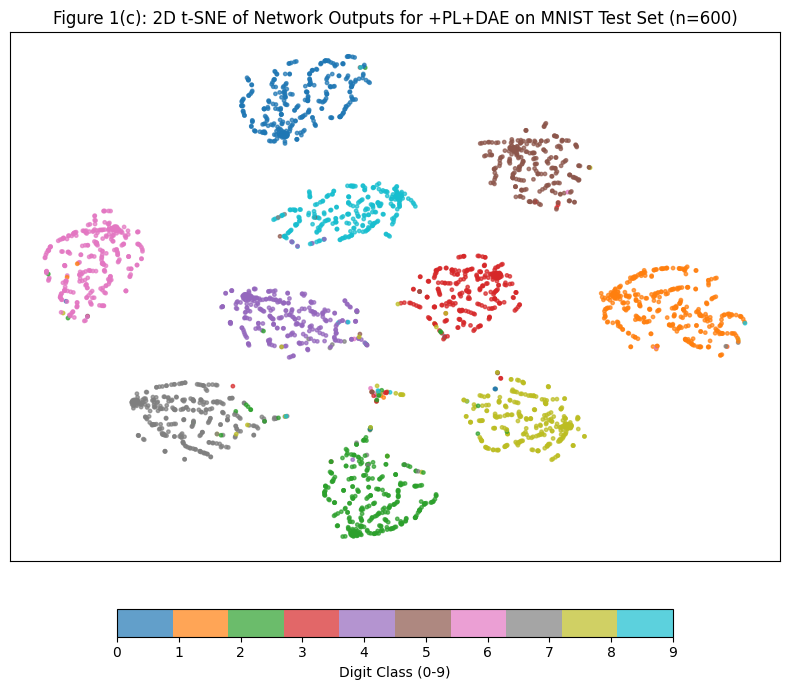

In [6]:
# shortcut: subsample 3000 test points for fast Colab t-SNE, upgrade to 10000 if desired
sub_g = torch.Generator().manual_seed(42)
sub_idx = torch.randperm(len(X_test), generator=sub_g)[:3000]
X_sub = X_test[sub_idx.to(device)]
y_sub = y_test[sub_idx.to(device)].cpu().numpy()

model_600.eval()
with torch.no_grad():
    probs_sub = model_600.predict_proba(X_sub).cpu().numpy()

tsne_2d = TSNE(n_components=2, random_state=42, init="pca", learning_rate="auto").fit_transform(probs_sub)

plt.figure(figsize=(8, 7))
scatter = plt.scatter(tsne_2d[:, 0], tsne_2d[:, 1], c=y_sub, cmap="tab10", s=6, alpha=0.7)
plt.colorbar(scatter, orientation="horizontal", fraction=0.046, pad=0.08, label="Digit Class (0-9)")
plt.title("Figure 1(c): 2D t-SNE of Network Outputs for +PL+DAE on MNIST Test Set (n=600)")
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()


## 6. Figure 2 Reproduction: First Hidden Layer Filter Visualization (DAE vs +PL+DAE)


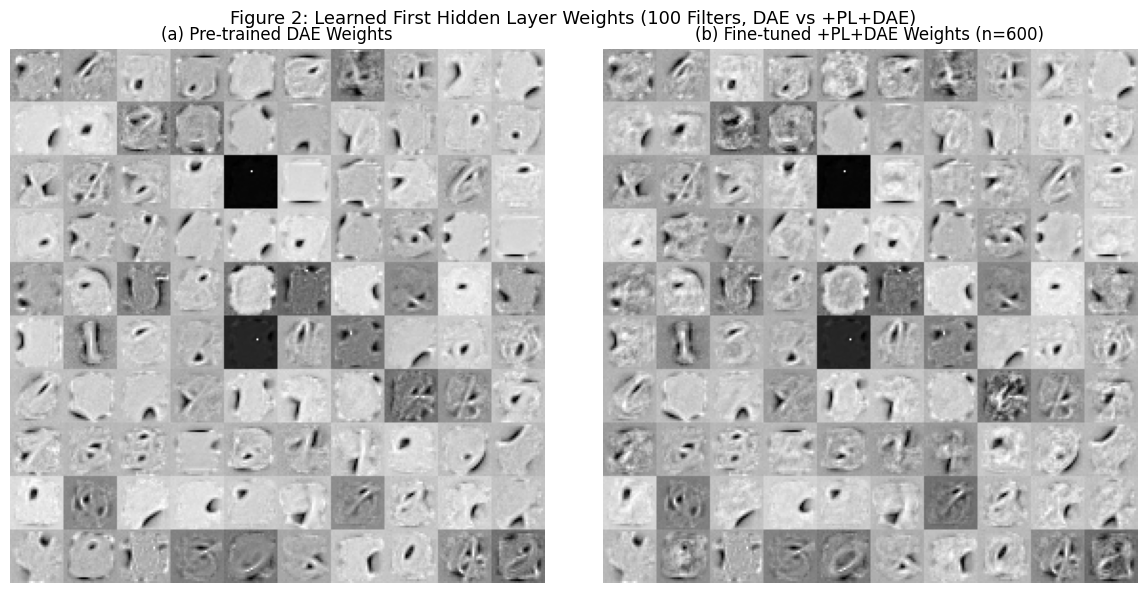

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

filter_sources = [
    ("(a) Pre-trained DAE Weights", dae_0.weight[:100].detach().cpu().view(100, 28, 28)),
    ("(b) Fine-tuned +PL+DAE Weights (n=600)", model_600.fc1.weight[:100].detach().cpu().view(100, 28, 28)),
]

for ax, (title, weights) in zip(axes, filter_sources):
    w_min = weights.amin(dim=(1, 2), keepdim=True)
    w_max = weights.amax(dim=(1, 2), keepdim=True)
    weights = (weights - w_min) / (w_max - w_min + 1e-8)
    grid = weights.view(10, 10, 28, 28).permute(0, 2, 1, 3).reshape(10 * 28, 10 * 28)
    ax.imshow(grid, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("Figure 2: Learned First Hidden Layer Weights (100 Filters, DAE vs +PL+DAE)", fontsize=13)
plt.tight_layout()
plt.show()
